# QEC Simulation with LocalASC

This walkthrough demonstrates a comlpete flow for QEC using the LocalASC scheduler for Syndrome extraction circuits: loading parity-check matrices, generating a valid CSS memory circuit, running a decoding experiment using `sinter`, and plotting the logical error rates.

## 1. Imports and Workspace Setup
First, we ensure the project root is in our path and import the necessary functions from the `circuit_builder`, `simulation`, and `visualization` modules.

In [1]:
import sys
import numpy as np
from pathlib import Path

# Find the repository root
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "codes").is_dir() and (path / "src").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the LocASC repository root.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.LocalASC.scheduling.localASC_scheduler import generate_schedule
from src.LocalASC.circuit_builder.circuit_builder import build_CSS_memory_circuit
from src.LocalASC.simulation.sinter_experiment import run_sinter_experiment
from src.LocalASC.visualization.processing_and_plotting import plot_qec_results

## 2. Generate the Schedule and Circuit
We will use the `[[12, 4, 2]]` code as our example. We load the parity-check matrices, generate an optimal CNOT schedule, and build stim memory circuits for X and Z- basis.

In [2]:
# load PCMs
code_dir = project_root / "codes" / "12_4"
Hx = np.loadtxt(code_dir / "TT_12_4_d2_Hx.txt", dtype=np.uint8)
Hz = np.loadtxt(code_dir / "TT_12_4_d2_Hz.txt", dtype=np.uint8)

# generate Schedule
schedule_path = project_root / "results" / "schedules" / "tutorial_12_4.csv"
schedule_path.parent.mkdir(parents=True, exist_ok=True)

success, status = generate_schedule(Hx, Hz, D=6, output_csv=str(schedule_path),solver_tlim=60)

print(f"Schedule generation: {status}")

# build and save the circuits
rounds = 2
circuit_z = build_CSS_memory_circuit(Hx, Hz, schedule_path, basis="Z", rounds=rounds)
circuit_x = build_CSS_memory_circuit(Hx, Hz, schedule_path, basis="X", rounds=rounds)

Schedule generation: OPTIMAL


## 3. Run the Sinter Decoding Experiment
With our circuit saved, we use the `sinter_experiment` module to sample the circuit across a range of physical error rates ($p$). The experiment output is saved as a JSON file.

In [3]:
experiment_output = project_root / "results" / "sinter_data"/ "Code_n12_k4" / "tutorial_12_4_results.json"
experiment_output.parent.mkdir(parents=True, exist_ok=True)

experiment_output_dir = project_root / "results" / "sinter_data" / "Code_n12_k4"


# define the physical error rates to go over
physical_error_rates = np.logspace(-4, -2, 10).tolist()

# Run the Sinter sampling experiment
run_sinter_experiment(
    base_circ_x=circuit_x,
    base_circ_z=circuit_z,
    physical_error_probs= physical_error_rates,
    filename="tutorial_12_4_results.json",
    name="12_4_2", #Only required for json metadata
    n=12,
    k=4,
    d=2,
    nrounds=2,
    max_errors=5000,
    max_bp_iter=10000,
    num_shots=1_000_000,
    output_dir= experiment_output_dir,
    verbose = False
    )

print(f"Experiment finished. Data saved to {experiment_output.relative_to(project_root)}")

Generating Sinter tasks for 10 noise levels...

Sinter execution complete in 352.17s.

Results for p = 1.0000e-04:
  > X-Basis: 5002/532241 mistakes
  > Z-Basis: 5003/525329 mistakes

Results for p = 1.6681e-04:
  > X-Basis: 5007/317201 mistakes
  > Z-Basis: 5010/325393 mistakes

Results for p = 2.7826e-04:
  > X-Basis: 5006/194833 mistakes
  > Z-Basis: 5014/193553 mistakes

Results for p = 4.6416e-04:
  > X-Basis: 5921/134050 mistakes
  > Z-Basis: 5019/113425 mistakes

Results for p = 7.7426e-04:
  > X-Basis: 5268/72930 mistakes
  > Z-Basis: 5004/70513 mistakes

Results for p = 1.2915e-03:
  > X-Basis: 5745/51202 mistakes
  > Z-Basis: 5691/51554 mistakes

Results for p = 2.1544e-03:
  > X-Basis: 5447/29602 mistakes
  > Z-Basis: 5201/28947 mistakes

Results for p = 3.5938e-03:
  > X-Basis: 6164/21651 mistakes
  > Z-Basis: 5709/20468 mistakes

Results for p = 5.9948e-03:
  > X-Basis: 5990/14195 mistakes
  > Z-Basis: 6126/14972 mistakes

Results for p = 1.0000e-02:
  > X-Basis: 5746/9959

## 4. Plot the Results
Finally, we use the plotting tools from `src.LocalASC.visualization.plotting` to read the generated JSON data, compute the pseudo-threshold, and visualize the logical error rate curve.

Computed pseudo-threshold: 0.0055


/home/ukech/Simula_UiB/Research/Code/LocASC/src/LocalASC/visualization/processing_and_plotting.py:93: RuntimeWarning: invalid value encountered in log
  p_ps = fsolve(lambda p: np.exp(poly(np.log(p))) - (1 - (1 - p)**k), 0.0055)[0]
/home/ukech/Simula_UiB/Research/Code/LocASC/src/LocalASC/visualization/processing_and_plotting.py:93: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  p_ps = fsolve(lambda p: np.exp(poly(np.log(p))) - (1 - (1 - p)**k), 0.0055)[0]


Saved plot image to /home/ukech/Simula_UiB/Research/Code/LocASC/results/plots/tutorial_12_4_ler_curve.jpg


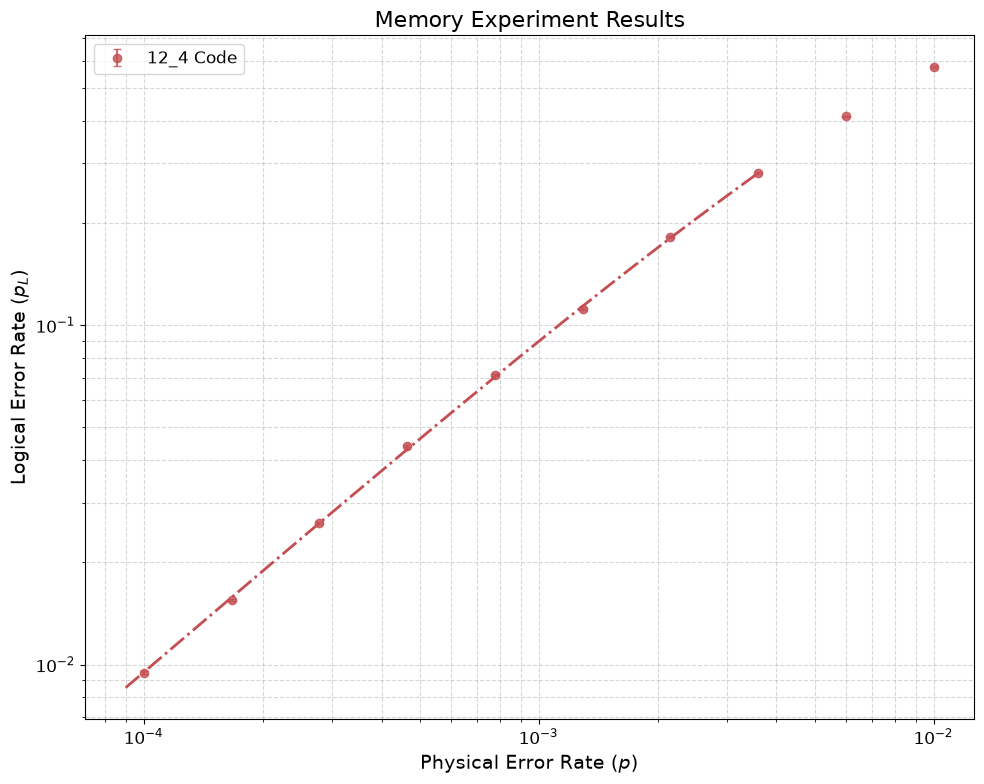

In [4]:
# Configure the plot: (filepath, color, marker, label, distance)
code_distance = 2 
file_configs = [
    (experiment_output, "#C44E52", "o", "12_4 Code", code_distance)
]

plot_save_path = project_root / "results" / "plots" / "tutorial_12_4_ler_curve.jpg"

# Generate the plot
plot_qec_results(
    file_configs=file_configs,
    save_path=plot_save_path
)